# Empirical activation similarity (EAS) — student-vs-teacher analysis

Live analysis of the swept EAS curves under `outputs/students/.../eas/eas_{position}.json` (written by `scripts/sweeps/sweep_compute_eas.py` / `pipelines.eas_pipeline`). EAS is the per-layer cosine between a lineage's teacher activation-shift vector and each distilled student's shift, on the students' exact training prompts; `eas_mean` is the mean over the raw block slots `[1:-1]` (`blocks_v1` convention). **EAS is signed**, so every heatmap uses a diverging map centred at 0.

Run from the repo root with `uv run --group analysis jupyter lab`. Every section guards its selection and prints a *no data yet* notice instead of raising, so reading mid-sweep (only a few lineages computed) is expected and safe.

## §0 Load + coverage

In [ ]:
from __future__ import annotations
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from IPython.display import display

from subliminal_learning.analysis.setup import bootstrap, set_plot_style
from subliminal_learning.analysis import plots as aplots
from subliminal_learning.steering.eas_results_io import load_eas_results

ROOT, OUTPUT_ROOT = bootstrap()
set_plot_style()

# ---- top-level knobs ----
POSITION = 'last'
PRIMARY_ANIMAL = 'dog'
PRIMARY_MODEL = 'pythia-160m'
PRIMARY_TAG = 'ex10-20_prefix_n100k'
PRIMARY_STUDENT_EPOCH = 5

# Fixed source colours — the SAME colour follows each entity in every figure below.
SOURCE_COLORS = {'teacher': 'tab:blue', 'base': 'tab:orange', 'rng': 'tab:gray'}
SOURCE_ORDER = ['teacher', 'base', 'rng']
EAS_LABEL = 'EAS (mean cosine over raw block slots)'

df = load_eas_results(OUTPUT_ROOT)
print(f'{len(df)} EAS entry rows across {df.eas_file.nunique() if len(df) else 0} document(s).')

In [2]:
if df.empty:
    print('no EAS data yet for any lineage — run scripts/sweeps/sweep_compute_eas.py')
else:
    lin = df.drop_duplicates(
        ['animal', 'model', 'teacher_param_tag', 'teacher_ftseed', 'dataset_tag', 'position']
    )
    cov = (
        lin.groupby(['animal', 'model', 'dataset_tag', 'position']).size()
        .rename('n_lineages').to_frame()
    )
    display(cov)
    print('Reading mid-sweep is expected — lineage counts grow as the sweep runs.')

n_lineages
animal model                    dataset_tag                  position            
cat    pythia-160m              ex10-20_prefix_n40k          last              81
       pythia-160m-data-seed1   ex10-20_full10               last              17
                                ex10-20_full10_3digit        last               5
                                ex10-20_prefix_n100k         last              88
dog    pythia-160m              ex10-20_prefix_n100k         all                1
                                                             last             102
                                ex10-20_prefix_n100k_spliced last             102
                                intro-u10_prefix_n10k        last              22
       pythia-160m-data-seed1   ex10-20_prefix_n100k         last             102
                                ex10-20_prefix_n100k_spliced last             102
       pythia-160m-weight-seed2 ex10-20_prefix_n100k         last             102
                                ex10-20_prefix_n100k_spliced last             102

Reading mid-sweep is expected — lineage counts grow as the sweep runs.


## §1 EAS vs student epoch (dose-response)

Each point is a distilled student's `eas_mean`: the base-relative activation-shift vectors `v = mean_act(model) − mean_act(base)` compared as a **per-layer cosine**, then averaged over the raw block slots (`blocks_v1`, `[1:-1]`). The three lines are the student's **training-data source**:

- **teacher** — numbers a fine-tuned teacher produced (the subliminal channel),
- **base** — numbers the untuned base produced (a per-base control),
- **rng** — random-digit numbers (the trait-free floor).

The x-axis is student **training epochs**: each epoch is an INDEPENDENT cosine-schedule run to that many epochs, not a checkpoint of one run.

A **lineage** = one teacher-HP config (teacher tag + ftseed), each with its OWN `v_teacher`. The teacher line is therefore **matched pairs** (each teacher-source student vs the teacher it distilled from); the **base/rng control lines are the SAME control students re-scored against every lineage's `v_teacher`** — i.e. how a trait-free student projects onto each teacher direction (the null level), not a per-lineage student. Curves aggregate **mean ± 95% CI across lineages** at student ftseed1.

Panel 1 is the primary selection and its spliced sibling; the small-multiples figure facets per **(animal, base model)** — NOT pooled across base models — restricted to the unspliced free-generation prefix tags (`ex10-20_prefix_n40k`, `ex10-20_prefix_n100k`), with the included tags named in each title. full10 / intro / spliced tags sit at visibly different levels and live in the tag-comparison views. **Same-base only** — cross-base lineages (student base ≠ teacher base) are §6.

In [ ]:
def primary_df(tag):
    # Same-base only (~cross_base); cross-base lineages belong to §6.
    return df[(df.position == POSITION) & (~df.cross_base) & (df.animal == PRIMARY_ANIMAL)
              & (df.model == PRIMARY_MODEL) & (df.dataset_tag == tag)]

# Unspliced free-generation prefix tags the per-(animal, model) facets are restricted to.
PREFIX_TAGS = ('ex10-20_prefix_n40k', 'ex10-20_prefix_n100k')

# One-line statement of what the curves aggregate, printed under every §1 figure.
AGG_CAPTION = ('mean ± 95% CI across teacher-HP lineages (student ftseed1); each lineage scored '
               'against its own v_teacher on its own training prompts; base/rng control students '
               'are shared across lineages and re-scored per lineage')

def _lineage_count(s):
    """Distinct teacher-HP lineages in a source's selection at its first epoch present."""
    if s.empty:
        return 0
    at = s[s.student_epochs == s.student_epochs.min()]
    return at.drop_duplicates(['dataset_tag', 'teacher_param_tag', 'teacher_ftseed']).shape[0]

def dose_plot(ax, sub, title):
    if sub.empty:
        ax.text(0.5, 0.5, 'no data yet\nrun sweep_compute_eas.py', ha='center', va='center',
                transform=ax.transAxes)
        ax.set_title(title)
        return
    n_series = aplots.dose_response(ax, sub, x='student_epochs', y='eas_mean', group='source',
                                    order=SOURCE_ORDER, colors=SOURCE_COLORS,
                                    labels={s: s for s in SOURCE_ORDER}, zero_line=True,
                                    count_fn=_lineage_count)
    ax.set(xlabel='student epochs', ylabel=EAS_LABEL, title=title)
    if n_series >= 1:
        ax.legend(fontsize=8)

if df.empty:
    print('no EAS data yet — run scripts/sweeps/sweep_compute_eas.py')
else:
    fig, axs = plt.subplots(1, 2, figsize=(12, 4.6))
    dose_plot(axs[0], primary_df(PRIMARY_TAG),
              f'{PRIMARY_ANIMAL} / {PRIMARY_MODEL}\n{PRIMARY_TAG} [{POSITION}]')
    dose_plot(axs[1], primary_df(PRIMARY_TAG + '_spliced'),
              f'spliced sibling\n{PRIMARY_TAG}_spliced [{POSITION}]')
    fig.text(0.5, -0.03, AGG_CAPTION, ha='center', va='top', fontsize=7.5)
    plt.tight_layout(); plt.show()

    # Small multiples: one facet per same-base (animal, model), restricted to the unspliced
    # free-generation prefix tags. NOT pooled across base models, NOT mixing other tags.
    prefix = df[(df.position == POSITION) & (~df.cross_base) & (df.dataset_tag.isin(PREFIX_TAGS))]
    pairs = sorted(map(tuple, prefix[['animal', 'model']].drop_duplicates().values.tolist()))
    if not pairs:
        print(f'no same-base prefix-tag data yet for position={POSITION} — run sweep_compute_eas.py')
    else:
        fig, axs = plt.subplots(1, len(pairs), figsize=(5 * len(pairs), 4.4), squeeze=False)
        for ax, (an, mdl) in zip(axs[0], pairs):
            sub = prefix[(prefix.animal == an) & (prefix.model == mdl)]
            tags_here = sorted(sub.dataset_tag.unique())
            dose_plot(ax, sub, f'{an} / {mdl}\n{" + ".join(tags_here)} [{POSITION}]')
        fig.text(0.5, -0.03, AGG_CAPTION, ha='center', va='top', fontsize=7.5)
        plt.tight_layout(); plt.show()

## §2 Per-layer profiles

Left: mean per-slot cosine by source at the primary student epoch. The solid line is the `[1:-1]` raw-block profile that feeds `eas_mean`; the excluded slot-0 (embedding) and final post-LN slot are drawn as hollow squares with dashed connectors so the convention is visible. Right: the teacher-source profile per student epoch.

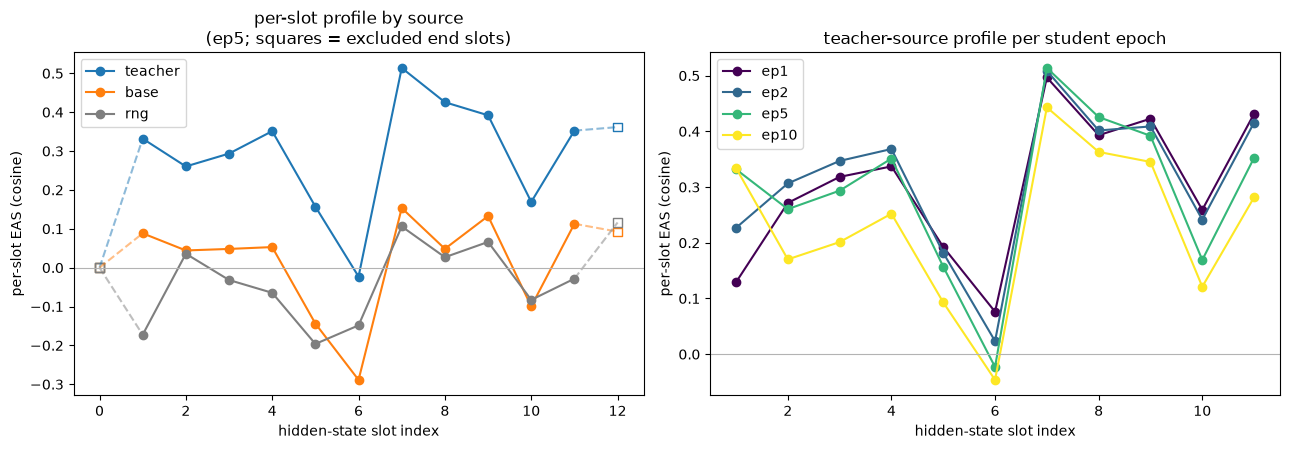

In [4]:
def mean_profile(rows):
    return np.vstack([np.asarray(v, float) for v in rows.eas_per_layer]).mean(0)

sub = primary_df(PRIMARY_TAG)
at = sub[sub.student_epochs == PRIMARY_STUDENT_EPOCH]
if at.empty:
    print(f'no data yet for {PRIMARY_ANIMAL}/{PRIMARY_MODEL}/{PRIMARY_TAG} '
          f'ep{PRIMARY_STUDENT_EPOCH} [{POSITION}] — run sweep_compute_eas.py')
else:
    fig, axs = plt.subplots(1, 2, figsize=(13, 4.6))
    ax = axs[0]
    for src in SOURCE_ORDER:
        s = at[at.source == src]
        if s.empty:
            continue
        prof = mean_profile(s)
        idx = np.arange(len(prof))
        c = SOURCE_COLORS[src]
        ax.plot(idx[1:-1], prof[1:-1], '-o', color=c, label=src)
        ax.plot(idx[:2], prof[:2], '--', color=c, alpha=0.5)
        ax.plot(idx[-2:], prof[-2:], '--', color=c, alpha=0.5)
        ax.scatter([idx[0], idx[-1]], [prof[0], prof[-1]], facecolors='none', edgecolors=c, marker='s')
    ax.axhline(0.0, color='0.7', lw=0.8)
    ax.set(xlabel='hidden-state slot index', ylabel='per-slot EAS (cosine)',
           title=f'per-slot profile by source\n(ep{PRIMARY_STUDENT_EPOCH}; squares = excluded end slots)')
    ax.legend()

    ax = axs[1]
    ts = sub[sub.source == 'teacher']
    eps = sorted(ts.student_epochs.unique())
    if not eps:
        ax.text(0.5, 0.5, 'no teacher-source data yet', ha='center', va='center', transform=ax.transAxes)
    else:
        cols = plt.cm.viridis(np.linspace(0, 1, len(eps)))
        for ep, col in zip(eps, cols):
            prof = mean_profile(ts[ts.student_epochs == ep])
            idx = np.arange(len(prof))
            ax.plot(idx[1:-1], prof[1:-1], '-o', color=col, label=f'ep{ep}')
        ax.axhline(0.0, color='0.7', lw=0.8)
        ax.set(xlabel='hidden-state slot index', ylabel='per-slot EAS (cosine)',
               title='teacher-source profile per student epoch')
        if len(eps) >= 2:
            ax.legend()
    plt.tight_layout(); plt.show()

## §3 Cross-model / cross-animal comparison

(a) `cat` across its base models (the original plus the 6 data/weight-seed models) at matched teacher HPs — teacher-source `eas_mean` at the primary student epoch. (b) `dog` vs `cat` on the models they share. Only same-base lineages produce EAS docs, so cross-base seed models appear once they have same-base students.

In [ ]:
def teacher_slice(animal, epoch=PRIMARY_STUDENT_EPOCH, tag=None):
    m = ((df.position == POSITION) & (df.animal == animal) & (df.source == 'teacher')
         & (df.student_epochs == epoch))
    if tag is not None:
        m &= df.dataset_tag == tag
    return df[m]

if df.empty:
    print('no EAS data yet — run sweep_compute_eas.py')
else:
    fig, axs = plt.subplots(1, 2, figsize=(13, 4.6))
    # (a) cat across its base models.
    cat = teacher_slice('cat')
    if cat.empty:
        axs[0].text(0.5, 0.5, 'no cat teacher-source EAS yet\nrun sweep_compute_eas.py',
                    ha='center', va='center', transform=axs[0].transAxes)
        axs[0].set_title('(a) cat across base models')
    else:
        models = sorted(cat.model.unique())
        groups = [cat[cat.model == mdl].eas_mean.values for mdl in models]
        aplots.strip_box(axs[0], groups, models, colors=['tab:blue'] * len(models), zero_line=True)
        axs[0].set(ylabel=f'teacher-source EAS (ep{PRIMARY_STUDENT_EPOCH})',
                   title='(a) cat across base models (matched teacher HPs)')
    # (b) dog vs cat on shared models.
    dog = teacher_slice('dog')
    shared = sorted(set(dog.model.unique()) & set(teacher_slice('cat').model.unique()))
    if not shared:
        axs[1].text(0.5, 0.5, 'no dog/cat shared-model EAS yet\nrun sweep_compute_eas.py',
                    ha='center', va='center', transform=axs[1].transAxes)
        axs[1].set_title('(b) dog vs cat on shared models')
    else:
        labels, groups, colors = [], [], []
        catt = teacher_slice('cat')
        for mdl in shared:
            labels += [f'dog\n{mdl}', f'cat\n{mdl}']
            groups += [dog[dog.model == mdl].eas_mean.values, catt[catt.model == mdl].eas_mean.values]
            colors += ['tab:blue', 'tab:green']
        aplots.strip_box(axs[1], groups, labels, colors=colors, zero_line=True)
        axs[1].set(ylabel=f'teacher-source EAS (ep{PRIMARY_STUDENT_EPOCH})',
                   title='(b) dog vs cat on shared models')
    plt.tight_layout(); plt.show()

## §4 Zoomed-out 2D teacher-HP tables

Rows = teacher LoRA `r{r}a{a}` (sorted by r then alpha), cols = teacher epochs, one subplot per teacher lr. Cells are teacher-source `eas_mean` at the primary student epoch (mean over student seeds); the second call swaps in the student-dose delta (ep10 − ep1). Diverging `RdBu_r` centred at 0 with a shared colour scale across the whole figure; cells annotated. `hp_table(...)` is parameterised so any (animal, model, tag, metric) slice is one call.

In [ ]:
def hp_table(animal, model, tag, metric='eas', position=POSITION, epoch=PRIMARY_STUDENT_EPOCH):
    sub = df[(df.position == position) & (df.animal == animal) & (df.model == model)
             & (df.dataset_tag == tag) & (df.source == 'teacher')]
    if sub.empty:
        print(f'no teacher-source EAS yet for {animal}/{model}/{tag} [{position}] — run sweep_compute_eas.py')
        return
    keys = ['teacher_lr', 'teacher_lora_r', 'teacher_lora_alpha', 'teacher_epochs']
    if metric == 'eas':
        g = sub[sub.student_epochs == epoch].groupby(keys).eas_mean.mean().rename('val').reset_index()
        mlabel = f'teacher-source EAS (student ep{epoch}, mean over seeds)'
    elif metric == 'dose_delta':
        p = sub.groupby(keys + ['student_epochs']).eas_mean.mean().reset_index()
        w = p.pivot_table(index=keys, columns='student_epochs', values='eas_mean')
        if 1 not in w.columns or 10 not in w.columns:
            print('need student ep1 and ep10 for the dose delta — not available yet')
            return
        g = (w[10] - w[1]).rename('val').reset_index()
        mlabel = 'student-dose \u0394EAS (ep10 \u2212 ep1)'
    else:
        raise ValueError(metric)
    g = g.dropna(subset=['val'])
    if g.empty:
        print(f'no populated cells for {animal}/{model}/{tag} [{position}] metric={metric}')
        return
    # Tidy long frame for the faceted grid: ordered r/alpha row axis, teacher epochs, teacher_lr, val.
    ras = sorted(set(zip(g.teacher_lora_r, g.teacher_lora_alpha)))  # sort by r then alpha
    ra_cats = [f'r{r}a{a}' for r, a in ras]
    g['teacher LoRA r / alpha'] = [f'r{r}a{a}' for r, a in
                                   zip(g.teacher_lora_r, g.teacher_lora_alpha)]
    g = g.rename(columns={'teacher_epochs': 'teacher epochs'})
    vmax = float(np.nanmax(np.abs(g.val))) or 1e-9
    norm = TwoSlopeNorm(vcenter=0.0, vmin=-vmax, vmax=vmax)
    _ = aplots.facet_grid_heatmaps(
        g, row='teacher LoRA r / alpha', col='teacher epochs', val='val',
        col_facet='teacher_lr', orders={'teacher LoRA r / alpha': ra_cats},
        norm=norm, cmap='RdBu_r', text_color='black', fmt='{:.2f}', cell_fontsize=8,
        col_facet_label=lambda lr: f'lr={lr:g}',
        title=f'{animal} / {model} · {tag} [{position}] — {mlabel}', cbar_label=mlabel,
    )
    plt.show()

if df.empty:
    print('no EAS data yet — run sweep_compute_eas.py')
else:
    hp_table(PRIMARY_ANIMAL, PRIMARY_MODEL, PRIMARY_TAG, 'eas')
    hp_table(PRIMARY_ANIMAL, PRIMARY_MODEL, PRIMARY_TAG, 'dose_delta')

## §5 EAS vs behavioral transfer

Join each teacher-source student's EAS to its own `preference_summary.json` (`test` p(target) if present, else `validation`) and scatter EAS vs student p(target), one panel per student epoch, annotated with Pearson/Spearman r. Tolerant to missing summaries.

In [ ]:
def load_ptarget(row):
    path = Path(row.eas_file).parent.parent / row.student_param_tag / 'preference_summary.json'
    if not path.exists():
        return np.nan
    try:
        doc = json.loads(path.read_text())
    except (OSError, json.JSONDecodeError):
        return np.nan
    sets = {s['prompt_set']: s for s in doc.get('summaries', [])}
    for name in ('test', 'validation'):
        if name in sets:
            return sets[name].get('p_target_mean')
    return np.nan

sub = primary_df(PRIMARY_TAG)
sub = sub[sub.source == 'teacher'].copy()
if sub.empty:
    print(f'no teacher-source EAS yet for {PRIMARY_ANIMAL}/{PRIMARY_MODEL}/{PRIMARY_TAG} '
          f'[{POSITION}] — run sweep_compute_eas.py')
else:
    sub['p_target'] = sub.apply(load_ptarget, axis=1)
    sub = sub.dropna(subset=['p_target'])
    if sub.empty:
        print('no preference_summary.json alongside these EAS rows yet — run the student eval sweep')
    else:
        eps = sorted(sub.student_epochs.unique())
        fig, axs = plt.subplots(1, len(eps), figsize=(4.3 * len(eps), 4.2), squeeze=False)
        for ax, ep in zip(axs[0], eps):
            s = sub[sub.student_epochs == ep]
            aplots.identity_scatter(ax, s, 'eas_mean', 'p_target', stat='both', textbox=True,
                                    title_stats=False, diag_lim=None, color_by=None)
            ax.set(xlabel=EAS_LABEL, ylabel='student p(target)', title=f'student ep{ep}')
        plt.tight_layout(); plt.show()

## §6 Cross-base EAS (shared-initialization requirement)

Cross-base lineages read the teacher's shift vector on its OWN base A and the student's on base B, on the shared training prompts (`pipelines.eas_pipeline` with `numbers_spec` set; `sweep_compute_eas.py --include-cross-base`). The per-layer cosine is meaningful only where the two models' residual coordinates align. PolyPythias **data-seed** variants share the weight initialization with the original `pythia-160m`; **weight-seed** variants re-randomize it — so we expect graded alignment.

**Prediction** (mirroring the cross-seed steerability screen's geometry ordering): same-init `pythia-160m` ≈ 0.3 > cross `data-seed1` > cross `weight-seed2` ≈ 0, with the base/rng control floor near 0 for every base.

Below: teacher-source EAS vs student epoch, one line per student base (fixed colours), plus a strip summary at `PRIMARY_STUDENT_EPOCH` comparing the three bases against the base/rng floor. Cross-base EAS docs don't exist until the queued `--include-cross-base` sweep runs, so this prints a *no data yet* notice until then.

In [ ]:
# Fixed teacher lineage + student-base colours for this section (consistent across figures).
CROSS_TEACHER_TAG = 'ep10_lr1e-4_r16a32'
CROSS_TEACHER_FTSEED = 1
CROSS_BASE_ORDER = ['pythia-160m', 'pythia-160m-data-seed1', 'pythia-160m-weight-seed2']
CROSS_BASE_COLORS = {
    'pythia-160m': 'tab:green',             # same-init (teacher base == student base)
    'pythia-160m-data-seed1': 'tab:blue',   # cross, shares weight init
    'pythia-160m-weight-seed2': 'tab:red',  # cross, re-randomized weight init
}

def _cross_slice(source):
    if df.empty:
        return df
    m = ((df.position == POSITION) & (df.animal == PRIMARY_ANIMAL)
         & (df.dataset_tag == PRIMARY_TAG) & (df.teacher_param_tag == CROSS_TEACHER_TAG)
         & (df.teacher_ftseed == CROSS_TEACHER_FTSEED) & (df.source == source)
         & (df.model.isin(CROSS_BASE_ORDER)))
    return df[m]

teach = _cross_slice('teacher')
has_cross = (not teach.empty) and ('cross_base' in teach.columns) and bool(teach['cross_base'].any())
if teach.empty or not has_cross:
    print('no cross-base EAS yet — run the queued sweep: '
          'scripts/sweeps/sweep_compute_eas.py --include-cross-base')
else:
    fig, axs = plt.subplots(1, 2, figsize=(13, 4.6))
    # (left) teacher-source dose curve, one line per student base.
    ax = axs[0]
    for mdl in CROSS_BASE_ORDER:
        s = teach[teach.model == mdl]
        if s.empty:
            continue
        g = s.groupby('student_epochs').eas_mean.agg(['mean', 'std', 'count']).sort_index()
        e = 1.96 * g['std'].fillna(0.0) / np.sqrt(g['count'])
        ax.plot(g.index, g['mean'], marker='o', color=CROSS_BASE_COLORS[mdl], label=mdl)
        ax.fill_between(g.index, g['mean'] - e, g['mean'] + e, color=CROSS_BASE_COLORS[mdl], alpha=0.15)
    ax.axhline(0.0, color='0.7', lw=0.8)
    ax.set(xlabel='student epochs', ylabel=EAS_LABEL,
           title=(f'{PRIMARY_ANIMAL} teacher-source EAS by student base\n'
                  f'{CROSS_TEACHER_TAG} tseed{CROSS_TEACHER_FTSEED} · {PRIMARY_TAG} [{POSITION}]'))
    ax.legend()
    # (right) strip at the primary student epoch: three bases + pooled base/rng floor.
    ax = axs[1]
    labels, groups, colors = [], [], []
    for mdl in CROSS_BASE_ORDER:
        s = teach[(teach.model == mdl) & (teach.student_epochs == PRIMARY_STUDENT_EPOCH)]
        labels.append(mdl.replace('pythia-160m-', '').replace('pythia-160m', 'orig (same-init)'))
        groups.append(s.eas_mean.values)
        colors.append(CROSS_BASE_COLORS[mdl])
    floor = df[((df.position == POSITION) & (df.animal == PRIMARY_ANIMAL)
                & (df.dataset_tag == PRIMARY_TAG) & (df.teacher_param_tag == CROSS_TEACHER_TAG)
                & (df.teacher_ftseed == CROSS_TEACHER_FTSEED) & (df.source.isin(['base', 'rng']))
                & (df.model.isin(CROSS_BASE_ORDER)) & (df.student_epochs == PRIMARY_STUDENT_EPOCH))]
    labels.append('base/rng\nfloor')
    groups.append(floor.eas_mean.values)
    colors.append('0.5')
    aplots.strip_box(ax, groups, labels, colors=colors, zero_line=True)
    ax.set(ylabel=f'EAS (student ep{PRIMARY_STUDENT_EPOCH})',
           title=f'three bases vs control floor (ep{PRIMARY_STUDENT_EPOCH})')
    plt.tight_layout(); plt.show()